# Preset and definition of variables

In [130]:
import os

import mne_nirs
import mne_nirs.io
from mne_nirs.channels import (get_long_channels,
                               get_short_channels,
                               picks_pair_to_idx)

import mne_bids.stats

import mne
import mne.io

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns



%matplotlib inline 

# 0. Select data

Load data / epochs / GLM LSA results and labels

In [131]:
# Participant id.

#p_id = ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07']


p_id = [ 'P01', 'P02', 'P03', 'P04', 'P05',
        'P06', 'P07', 'S01', 'S02', 'S03', 
        'S04',  'S06', 'S07', 'S09', 'S10']


# write data_path using p_id.
data_path = os.path.join('..', 'data', 'dataset', 'derivatives', 'mne-nirs')

print(data_path)

# Run id.
run_id = ['1', '2']



../data/dataset/derivatives/mne-nirs


Get snirf file. Load data to the raw_intensity variable.

In [132]:


# Create an empty list to store the raw intensity data
betas_files = []

for p in p_id:

    # particiapnt directory
    p_dir = os.path.join(data_path, p)

    # Get files with .csv extension using os
    csv_files = [os.path.join(p_dir, f) for f in os.listdir(p_dir) if f.endswith('.csv')]

    for r in run_id:

        print(f'Participant: {p}, Run: {r}')

        # select file that contains 'run-' + run_id in its name
        csv_file = [f for f in csv_files if f'run-{r}' in f]
        
        
        #csv_file = [f for f in csv_files if r in f]

        if csv_file:

            # append the csv_file to the betas_files list
            betas_files.append(csv_file[0])
            print(f'csv file found: {csv_file[0]}')

            
        else:
            
            print('No csv file found')



Participant: P01, Run: 1
csv file found: ../data/dataset/derivatives/mne-nirs/P01/sub-P01_run-1_glm_lsa.csv
Participant: P01, Run: 2
csv file found: ../data/dataset/derivatives/mne-nirs/P01/sub-P01_run-2_glm_lsa.csv
Participant: P02, Run: 1
No csv file found
Participant: P02, Run: 2
csv file found: ../data/dataset/derivatives/mne-nirs/P02/sub-P02_run-2_glm_lsa.csv
Participant: P03, Run: 1
No csv file found
Participant: P03, Run: 2
csv file found: ../data/dataset/derivatives/mne-nirs/P03/sub-P03_run-2_glm_lsa.csv
Participant: P04, Run: 1
csv file found: ../data/dataset/derivatives/mne-nirs/P04/sub-P04_run-1_glm_lsa.csv
Participant: P04, Run: 2
No csv file found
Participant: P05, Run: 1
csv file found: ../data/dataset/derivatives/mne-nirs/P05/sub-P05_run-1_glm_lsa.csv
Participant: P05, Run: 2
csv file found: ../data/dataset/derivatives/mne-nirs/P05/sub-P05_run-2_glm_lsa.csv
Participant: P06, Run: 1
csv file found: ../data/dataset/derivatives/mne-nirs/P06/sub-P06_run-1_glm_lsa.csv
Partici

In [133]:
betas_files

['../data/dataset/derivatives/mne-nirs/P01/sub-P01_run-1_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P01/sub-P01_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P02/sub-P02_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P03/sub-P03_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P04/sub-P04_run-1_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P05/sub-P05_run-1_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P05/sub-P05_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P06/sub-P06_run-1_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P06/sub-P06_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P07/sub-P07_run-1_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/P07/sub-P07_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/S01/sub-S01_run-1_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/S01/sub-S01_run-2_glm_lsa.csv',
 '../data/dataset/derivatives/mne-nirs/S02/sub-S02_run-1_glm_lsa.csv',
 '../d

In [134]:
# create a dataframe to store the betas_files data
df_features = pd.DataFrame()

# loop through the betas_files
for f in betas_files:

    
    # read the csv file
    df_ = pd.read_csv(f)

    # add col with participant id
    df_['participant_id'] = f.split('/')[-2]

    # add col with run id   
    df_['run_id'] = f.split('/')[-1].split('_')[1]

    
    
    # concat the data to the df dataframe
    df_features = pd.concat([df_features, df_], axis=0)

# 1. Define input data X and labels vector Y

The rows corresponding to the epochs of interest.


In [135]:
# get rows corresponding to the conditions M*
df_features_M = df_features[df_features['Condition'].str.contains('M')]

# df_features_subset = df_features[df_features['Condition'].str.contains('Baseline|M')]

In [136]:
df_features_M.head()


,Unnamed: 0,Condition,df,mse,p_value,se,t,theta,Source,Detector,Chroma,Significant,ch_name,participant_id,run_id
17,6353,M1_001,99.0,2.189612e-18,3.095081e-05,8.177470e-09,-4.367670,-3.571649e-08,1,1,hbo,True,S1_D1 hbo,P01,run-1
18,6354,M1_002,99.0,2.189612e-18,7.385951e-27,9.816574e-09,-14.812328,-1.454063e-07,1,1,hbo,True,S1_D1 hbo,P01,run-1
19,6355,M1_003,99.0,2.189612e-18,7.368871e-08,1.078946e-08,-5.817187,-6.276434e-08,1,1,hbo,True,S1_D1 hbo,P01,run-1
20,6356,M2_001,99.0,2.189612e-18,7.689327e-04,8.293964e-09,3.471358,2.879132e-08,1,1,hbo,True,S1_D1 hbo,P01,run-1
21,6357,M2_002,99.0,2.189612e-18,9.818987e-02,1.117905e-08,-1.669438,-1.866273e-08,1,1,hbo,False,S1_D1 hbo,P01,run-1


In [137]:
# print the number of rows in df_features_M
print('Number of rows in df_features_M:', len(df_features_M))

Number of rows in df_features_M: 63504


In [138]:
# create a input data matrix X 
features_list = []

labels = []

groups = []

# Get unique values of the 'Condition' column
conditions = df_features_M['Condition'].unique()

channels = df_features_M['ch_name'].unique()

for condition in conditions:

   

    # get rows corresponding to the condition 
    df_condition = df_features_M[df_features_M['Condition'] == condition]

    # print number of rows
    # print(f'Number of rows for condition {condition}: {df_condition.shape[0]}')
    

    # for each pair participant_id & run_id in the df_condition get the features
    for (participant_id, run_id), df_participant in df_condition.groupby(['participant_id', 'run_id']):

        # get the features from the 't' column in the rows that have 'hbo' in ch_name 
        features = df_participant[df_participant['ch_name'].str.contains('hb')]['t'].values
        
        # append the features to the features_list
        features_list.append(features)

        # append the condition to the labels
        labels.append([condition[:2]])

        # append the participant_id to the groups
        groups.append(participant_id)   


 
    
# print number of events
print('Number of events:', len(features_list))

# print the number of labels
print('Number of labels:', len(labels))

# print the number of groups
print('Number of groups:', len(groups))

Number of events: 324
Number of labels: 324
Number of groups: 324


In [139]:
print(labels)

print(groups)

[['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M1'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'], ['M2'],

# 2. Classification.

In [140]:
features_list

[array([ -4.36766975,  -5.25459337,   7.33571851,  -5.15146803,
         -2.7859057 ,   2.00722464, -11.63242873,  -9.59960393,
         -6.46145712,  -5.70565634,  -2.84533996,  -8.48917441,
         -2.36481945,   1.33602206,  -3.69314019,  -4.8669108 ,
         10.27945329,  10.01623248,   3.04422272,   8.20700894,
         -0.51002762,   3.41577036,  -4.17938518,  -2.68384568,
         -0.96681951,   6.76797807,  -9.11449663, -10.22946856,
         -1.38589052,  -2.46472787,   2.13400215,   3.86200419,
         12.17965111,   7.96097421,  -4.10834849,  -2.58924916,
         -7.0204105 ,  -1.15644453,   2.07459623,  16.83988824,
         10.25905951,   4.08230394, -17.87118015,   0.91179015,
          0.19035339, -12.84653492,   5.35231714,   5.2398923 ,
         16.47040888,  10.39734106,   3.22958296,  -0.34063097,
          3.93751713,   4.67560523,   1.05588245,  10.49804354,
         10.93738412,  12.6099588 ,  16.53468468,   1.47722852,
         -0.17125157,  -9.28567121,   5.

In [141]:
X = np.array(features_list)

y = labels


In [142]:
X.shape, len(y), len(groups)    

((324, 196), 324, 324)

In [143]:
# transform unique values of y into numebrs from 0 to n_classes - 1
y_class = np.unique(y, return_inverse=True)[1] + 1

print(y_class)


# change the first char from the string in each element of groups and P = 0 and S = 1
groups_class = [100 if g[0] == 'P' else 0 for g in groups]

# add the rest of the string to the number
groups_class = [int(g[1:]) + groups_class[i] for i, g in enumerate(groups)]


print(groups_class)



[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4
 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4 4]
[101, 101, 102, 103, 104, 105, 105, 106, 106, 107, 107, 1, 1, 2, 2, 3, 3, 4, 4, 6, 6, 7, 7, 9, 9, 10, 10, 101, 101, 102, 103, 104, 105, 105, 106, 106, 107, 107, 1, 1, 2, 2, 3, 3, 4, 4, 6, 6, 7, 7, 9, 9, 10, 10, 101, 101, 102, 103, 104, 105, 105, 106, 106, 107, 107, 1, 1, 2, 2, 3, 3, 4, 4, 6, 6, 7, 7, 9, 9, 10, 10, 101, 101, 102, 103, 104, 1

In [144]:
X.shape 

(324, 196)

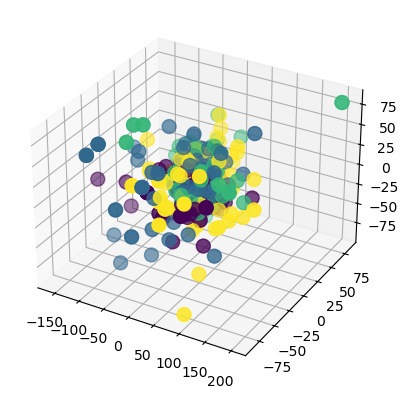

In [145]:
# pca plot of X, colored based on y
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=y_class, cmap='viridis', s=100)

plt.show()



## 2.1 Dummy classifier

In [146]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RepeatedKFold
from sklearn.model_selection import cross_val_score


clf_dummy = DummyClassifier( strategy='stratified')

skf = RepeatedKFold(n_splits=10, n_repeats=100)

scores_dummy = cross_val_score(clf_dummy, X, y, cv=skf, scoring='accuracy')

print(np.mean(scores_dummy), scores_dummy.std())


0.2463589015151515 0.07489377913284455


(array([  3.,  27.,  62., 169., 331., 204., 132.,  54.,  13.,   5.]),
 array([0.        , 0.05151515, 0.1030303 , 0.15454545, 0.20606061,
        0.25757576, 0.30909091, 0.36060606, 0.41212121, 0.46363636,
        0.51515152]),
 <BarContainer object of 10 artists>)

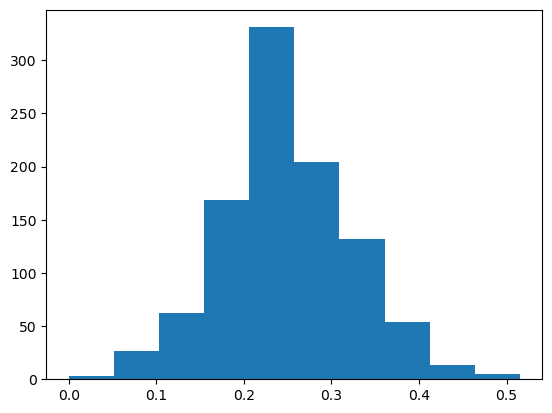

In [147]:
# histogram of res
plt.hist(scores_dummy, bins=10)

## 2.2 Classification using SVM

In [148]:
from sklearn import svm
from sklearn.model_selection import train_test_split

from numpy import ravel


clf = svm.SVC(kernel='linear', C=1, random_state=42)

skf = RepeatedKFold(n_splits=10, n_repeats=100)

scores = cross_val_score(clf, X, ravel(y), cv=skf, scoring='accuracy')

print(scores.mean(), scores.std())

0.7752736742424242 0.07065026247572496


(array([  3.,  27.,  62., 169., 331., 204., 132.,  54.,  13.,   5.]),
 array([0.        , 0.05151515, 0.1030303 , 0.15454545, 0.20606061,
        0.25757576, 0.30909091, 0.36060606, 0.41212121, 0.46363636,
        0.51515152]),
 <BarContainer object of 10 artists>)

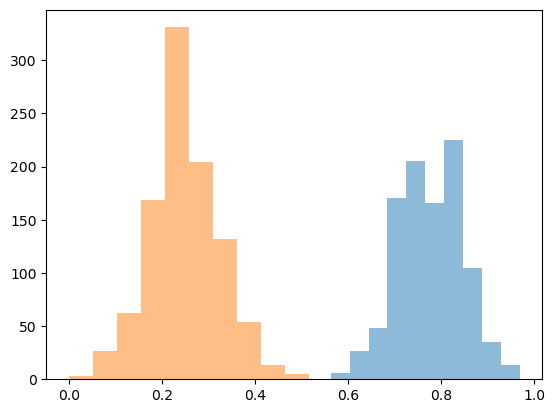

In [149]:
# histogram of scores and scores_dummy with different colors
plt.hist(scores, bins=10, alpha=0.5, label='SVM')
plt.hist(scores_dummy, bins=10, alpha=0.5, label='Dummy')

## 2.3. Leave one group out

In [150]:

from sklearn import svm
from sklearn.model_selection import train_test_split

from sklearn.model_selection import LeaveOneGroupOut

logo = LeaveOneGroupOut()
logo.get_n_splits(X, y_class, groups_class)


clf = svm.SVC(kernel='linear')

scores = cross_val_score(clf, 
                         X, 
                         ravel(y), 
                         cv=logo, 
                         groups=groups_class, 
                         scoring='accuracy')

print(f'mean accuracy {np.mean(scores)} and std {scores.std()}')




mean accuracy 0.3277777777777778 and std 0.2796602877478494


[[31 23 19  8]
 [23 27 17 14]
 [23 26 21 11]
 [26 23 10 22]]


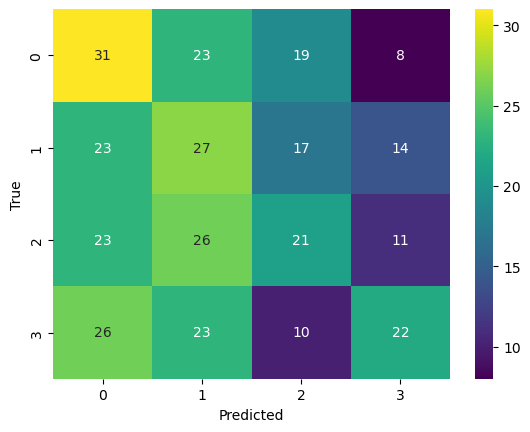

In [151]:
# display the confusion matrix
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(clf, X, ravel(y), cv=logo, groups=groups_class)

conf_mat = confusion_matrix(ravel(y), y_pred)

print(conf_mat)

# plot the confusion matrix
import seaborn as sns

sns.heatmap(conf_mat, annot=True, fmt='d', cmap='viridis')

plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()


In [152]:
# skf = RepeatedRepeatedStratifiedKFoldKFold(n_splits=2, n_repeats=100)

In [153]:
for i, (train_index, test_index) in enumerate(logo.split(X, y_class, groups_class)):
    
    print(f"Fold {i}:")
    print(f"  Train: index={train_index}, group={np.array(groups_class)[train_index]}")
    print(f"  Test:  index={test_index}, group={np.array(groups_class)[test_index]}")


Fold 0:
  Train: index=[  0   1   2   3   4   5   6   7   8   9  10  13  14  15  16  17  18  19
  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36  37
  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55  56  57
  58  59  60  61  62  63  64  67  68  69  70  71  72  73  74  75  76  77
  78  79  80  81  82  83  84  85  86  87  88  89  90  91  94  95  96  97
  98  99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115
 116 117 118 121 122 123 124 125 126 127 128 129 130 131 132 133 134 135
 136 137 138 139 140 141 142 143 144 145 148 149 150 151 152 153 154 155
 156 157 158 159 160 161 162 163 164 165 166 167 168 169 170 171 172 175
 176 177 178 179 180 181 182 183 184 185 186 187 188 189 190 191 192 193
 194 195 196 197 198 199 202 203 204 205 206 207 208 209 210 211 212 213
 214 215 216 217 218 219 220 221 222 223 224 225 226 229 230 231 232 233
 234 235 236 237 238 239 240 241 242 243 244 245 246 247 248 249 250 251
 252 253 256 257 258 259 260

In [154]:
# Get weights of the features
clf.fit(X, y)

mean_feature_coef = np.sum(np.abs(clf.coef_), 0)

mean_feature_coef

array([0.07522201, 0.02441628, 0.02736874, 0.07876007, 0.03649411,
       0.03282159, 0.05848989, 0.04818924, 0.03919112, 0.03069204,
       0.03458449, 0.04315612, 0.1015803 , 0.07277618, 0.0818496 ,
       0.04934328, 0.02302668, 0.04884249, 0.04572439, 0.00659946,
       0.02511451, 0.06067466, 0.06114627, 0.05768634, 0.07290958,
       0.13743257, 0.04775131, 0.08670117, 0.05433032, 0.06255524,
       0.05941132, 0.0501263 , 0.04450382, 0.04781836, 0.04058337,
       0.05043451, 0.07292466, 0.04770891, 0.07303097, 0.07924008,
       0.03726132, 0.09164759, 0.04363646, 0.06228995, 0.05065433,
       0.09408014, 0.07317195, 0.06429363, 0.0629972 , 0.05450388,
       0.05331894, 0.02213302, 0.05411307, 0.09003099, 0.07460557,
       0.05256667, 0.04268512, 0.06899933, 0.02256892, 0.05817699,
       0.10611378, 0.0698012 , 0.04738225, 0.10673936, 0.07304175,
       0.04130795, 0.03362111, 0.04169676, 0.04711801, 0.02874695,
       0.04548618, 0.09451221, 0.040848  , 0.12595552, 0.06849

In [155]:

sorted_idx = np.argsort(mean_feature_coef)


In [156]:
# sort channels based on the sorted indexes
sorted_channels = [channels[i] for i in sorted_idx]

sorted_channels


['S7_D7 hbo',
 'S22_D20 hbr',
 'S13_D8 hbr',
 'S15_D10 hbr',
 'S22_D22 hbr',
 'S23_D21 hbr',
 'S17_D15 hbo',
 'S19_D16 hbo',
 'S7_D3 hbo',
 'S18_D17 hbr',
 'S1_D2 hbo',
 'S8_D4 hbo',
 'S28_D25 hbo',
 'S1_D28 hbo',
 'S13_D13 hbr',
 'S9_D5 hbr',
 'S2_D2 hbr',
 'S14_D12 hbr',
 'S30_D27 hbo',
 'S23_D19 hbo',
 'S29_D25 hbo',
 'S15_D14 hbr',
 'S4_D3 hbo',
 'S21_D21 hbr',
 'S27_D23 hbo',
 'S27_D5 hbo',
 'S17_D15 hbr',
 'S2_D4 hbo',
 'S22_D20 hbo',
 'S7_D6 hbr',
 'S28_D25 hbr',
 'S8_D8 hbr',
 'S31_D2 hbo',
 'S4_D5 hbo',
 'S17_D14 hbr',
 'S2_D4 hbr',
 'S32_D27 hbo',
 'S29_D25 hbr',
 'S16_D11 hbr',
 'S17_D18 hbr',
 'S10_D7 hbr',
 'S2_D2 hbo',
 'S13_D11 hbr',
 'S13_D13 hbo',
 'S10_D8 hbr',
 'S4_D26 hbr',
 'S19_D15 hbr',
 'S4_D5 hbr',
 'S28_D24 hbo',
 'S4_D2 hbo',
 'S15_D12 hbr',
 'S12_D9 hbo',
 'S25_D24 hbr',
 'S21_D20 hbr',
 'S24_D20 hbo',
 'S21_D21 hbo',
 'S22_D22 hbo',
 'S31_D2 hbr',
 'S1_D1 hbr',
 'S31_D27 hbr',
 'S19_D14 hbo',
 'S16_D13 hbr',
 'S4_D26 hbo',
 'S14_D12 hbo',
 'S23_D23 hbr',
 '

In [157]:
# get hbo channels from channels
hbo_channels = df_features_M[df_features_M['ch_name'].str.contains('hbo')]['ch_name'].unique()

print(hbo_channels)

# Get the mean_feature_coef for hbo channels
mean_feature_coef_hbo = mean_feature_coef[[channels.tolist().index(ch) for ch in hbo_channels]]

['S1_D1 hbo' 'S1_D2 hbo' 'S1_D28 hbo' 'S2_D1 hbo' 'S2_D2 hbo' 'S2_D4 hbo'
 'S3_D1 hbo' 'S3_D4 hbo' 'S4_D2 hbo' 'S4_D3 hbo' 'S4_D5 hbo' 'S4_D26 hbo'
 'S5_D3 hbo' 'S5_D4 hbo' 'S5_D6 hbo' 'S6_D4 hbo' 'S7_D3 hbo' 'S7_D5 hbo'
 'S7_D6 hbo' 'S7_D7 hbo' 'S8_D4 hbo' 'S8_D6 hbo' 'S8_D8 hbo' 'S9_D5 hbo'
 'S9_D7 hbo' 'S9_D9 hbo' 'S9_D23 hbo' 'S10_D6 hbo' 'S10_D7 hbo'
 'S10_D8 hbo' 'S10_D10 hbo' 'S11_D8 hbo' 'S11_D11 hbo' 'S12_D7 hbo'
 'S12_D9 hbo' 'S12_D10 hbo' 'S12_D12 hbo' 'S13_D8 hbo' 'S13_D10 hbo'
 'S13_D11 hbo' 'S13_D13 hbo' 'S14_D9 hbo' 'S14_D12 hbo' 'S14_D19 hbo'
 'S15_D10 hbo' 'S15_D12 hbo' 'S15_D13 hbo' 'S15_D14 hbo' 'S16_D11 hbo'
 'S16_D13 hbo' 'S17_D14 hbo' 'S17_D15 hbo' 'S17_D18 hbo' 'S18_D15 hbo'
 'S18_D17 hbo' 'S18_D18 hbo' 'S19_D14 hbo' 'S19_D15 hbo' 'S19_D16 hbo'
 'S20_D15 hbo' 'S20_D16 hbo' 'S20_D17 hbo' 'S21_D18 hbo' 'S21_D19 hbo'
 'S21_D20 hbo' 'S21_D21 hbo' 'S22_D20 hbo' 'S22_D22 hbo' 'S23_D9 hbo'
 'S23_D19 hbo' 'S23_D21 hbo' 'S23_D23 hbo' 'S24_D20 hbo' 'S24_D21 hbo'
 'S24_D22 

In [158]:
# get hbr channels from channels
hbr_channels = df_features_M[df_features_M['ch_name'].str.contains('hbr')]['ch_name'].unique()

print(hbr_channels)

# Get the mean_feature_coef for hbo channels
mean_feature_coef_hbr = mean_feature_coef[[channels.tolist().index(ch) for ch in hbr_channels]]

['S1_D1 hbr' 'S1_D2 hbr' 'S1_D28 hbr' 'S2_D1 hbr' 'S2_D2 hbr' 'S2_D4 hbr'
 'S3_D1 hbr' 'S3_D4 hbr' 'S4_D2 hbr' 'S4_D3 hbr' 'S4_D5 hbr' 'S4_D26 hbr'
 'S5_D3 hbr' 'S5_D4 hbr' 'S5_D6 hbr' 'S6_D4 hbr' 'S7_D3 hbr' 'S7_D5 hbr'
 'S7_D6 hbr' 'S7_D7 hbr' 'S8_D4 hbr' 'S8_D6 hbr' 'S8_D8 hbr' 'S9_D5 hbr'
 'S9_D7 hbr' 'S9_D9 hbr' 'S9_D23 hbr' 'S10_D6 hbr' 'S10_D7 hbr'
 'S10_D8 hbr' 'S10_D10 hbr' 'S11_D8 hbr' 'S11_D11 hbr' 'S12_D7 hbr'
 'S12_D9 hbr' 'S12_D10 hbr' 'S12_D12 hbr' 'S13_D8 hbr' 'S13_D10 hbr'
 'S13_D11 hbr' 'S13_D13 hbr' 'S14_D9 hbr' 'S14_D12 hbr' 'S14_D19 hbr'
 'S15_D10 hbr' 'S15_D12 hbr' 'S15_D13 hbr' 'S15_D14 hbr' 'S16_D11 hbr'
 'S16_D13 hbr' 'S17_D14 hbr' 'S17_D15 hbr' 'S17_D18 hbr' 'S18_D15 hbr'
 'S18_D17 hbr' 'S18_D18 hbr' 'S19_D14 hbr' 'S19_D15 hbr' 'S19_D16 hbr'
 'S20_D15 hbr' 'S20_D16 hbr' 'S20_D17 hbr' 'S21_D18 hbr' 'S21_D19 hbr'
 'S21_D20 hbr' 'S21_D21 hbr' 'S22_D20 hbr' 'S22_D22 hbr' 'S23_D9 hbr'
 'S23_D19 hbr' 'S23_D21 hbr' 'S23_D23 hbr' 'S24_D20 hbr' 'S24_D21 hbr'
 'S24_D22 

## 2.4 RandomForest

In [159]:

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split

from sklearn.model_selection import LeaveOneGroupOut

logo = LeaveOneGroupOut()
logo.get_n_splits(X, y_class, groups_class)


clf = RandomForestClassifier(max_depth=None, random_state=0)

# X = np.random.rand(X.shape[0], X.shape[1])

scores = cross_val_score(clf, X, ravel(y), cv=logo, groups=groups_class, scoring='accuracy')

print(np.mean(scores), scores.std())


0.4166666666666667 0.2590938625858004


In [160]:
scores

array([0.33333333, 0.16666667, 0.25      , 0.33333333, 0.29166667,
       0.375     , 0.29166667, 0.33333333, 1.        , 0.66666667,
       1.        , 0.08333333, 0.375     , 0.41666667, 0.33333333])

[[0.61728395 0.11111111 0.12345679 0.14814815]
 [0.22222222 0.34567901 0.22222222 0.20987654]
 [0.20987654 0.14814815 0.33333333 0.30864198]
 [0.27160494 0.20987654 0.22222222 0.2962963 ]]


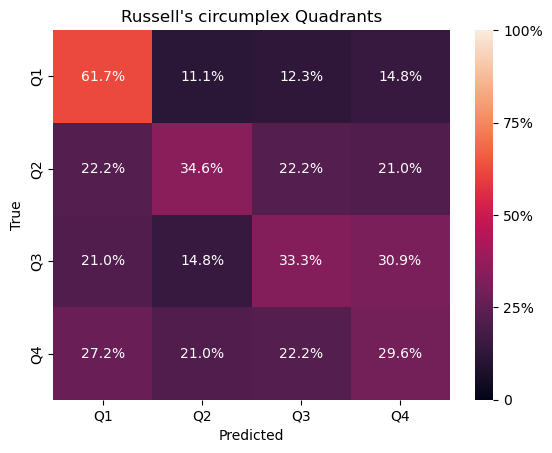

In [161]:
# display the confusion matrix
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(clf, X, ravel(y), cv=logo, groups=groups_class)

conf_mat = confusion_matrix(ravel(y), y_pred, normalize='true')

print(conf_mat)

# plot the confusion matrix
import seaborn as sns

q_labels = ['Q1', 'Q2', 'Q3', 'Q4']
ax = sns.heatmap(conf_mat, annot=True, 
            fmt='.1%', 
            xticklabels=q_labels, 
            yticklabels=q_labels, vmin=0, vmax=1)

cbar = ax.collections[0].colorbar
cbar.set_ticks([0, .25, 0.5, .75, 1])
cbar.set_ticklabels(['0', '25%', '50%', '75%', '100%'])

plt.xlabel('Predicted')
plt.ylabel('True')

# title
plt.title('Russell\'s circumplex Quadrants')

plt.show()

### 2.4.1 interpretation of weights

In [162]:
clf.fit(X, ravel(y))

RandomForestClassifier(random_state=0)

In [163]:
feature_importance = clf.feature_importances_

# max min scale the feature_importance
print(np.max(feature_importance), np.min(feature_importance))

0.012582106294128523 0.0018598021759195131


In [193]:
topnfeats  = 10
sorted_idx = np.argsort(np.abs(feature_importance))[::-1][:topnfeats]

# sort channels based on the sorted indexes
sorted_channels = [channels[i] for i in sorted_idx]

sorted_channels

['S28_D24 hbr',
 'S8_D8 hbo',
 'S26_D24 hbo',
 'S21_D19 hbo',
 'S25_D21 hbo',
 'S20_D16 hbr',
 'S30_D27 hbr',
 'S2_D4 hbo',
 'S26_D22 hbo',
 'S15_D12 hbo']

In [165]:
# get hbo channels from channels
hbo_channels = df_features_M[df_features_M['ch_name'].str.contains('hbo')]['ch_name'].unique()

# Get the mean_feature_coef for hbo channels
mean_feature_coef_hbo = feature_importance[[channels.tolist().index(ch) for ch in hbo_channels]]


In [166]:
# get hbr channels from channels
hbr_channels = df_features_M[df_features_M['ch_name'].str.contains('hbr')]['ch_name'].unique()


# Get the mean_feature_coef for hbo channels
mean_feature_coef_hbr = feature_importance[[channels.tolist().index(ch) for ch in hbr_channels]]



# 3. Feature selection

In [167]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif


# X_sel = SelectKBest(mutual_info_classif, k=10).fit_transform(X, y)

# transform all values of y into numeric values

y_df = pd.Series(y)

from mrmr import mrmr_classif

X_df = pd.DataFrame(X)
y_df = pd.Series(np.unique(y, return_inverse=True)[1]
)

selected_features = mrmr_classif(X=X_df, y=y_df, K=20)

100%|██████████| 20/20 [00:00<00:00, 70.26it/s]


In [168]:
selected_features

X_sel = X[:, selected_features]

In [169]:
logo = LeaveOneGroupOut()
logo.get_n_splits(X_sel, y_class, groups_class)


clf = svm.SVC(kernel='linear')

# X = np.random.rand(X.shape[0], X.shape[1])

scores = cross_val_score(clf, X_sel, ravel(y), cv=logo, groups=groups_class, scoring='accuracy')

print(np.mean(scores), scores.std())

0.4305555555555555 0.22906142364542556


[[0.54320988 0.09876543 0.16049383 0.19753086]
 [0.2345679  0.41975309 0.13580247 0.20987654]
 [0.32098765 0.13580247 0.39506173 0.14814815]
 [0.2345679  0.28395062 0.17283951 0.30864198]]


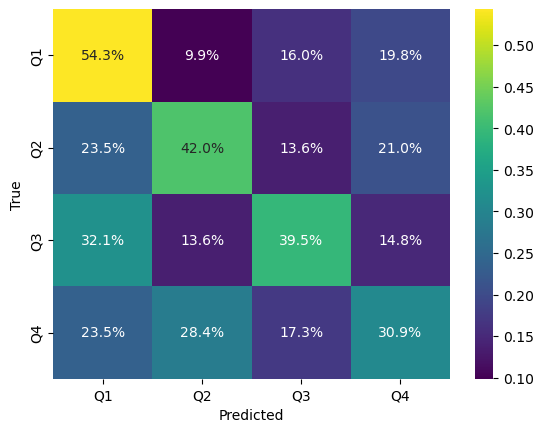

In [170]:
# display the confusion matrix
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(clf, X_sel, ravel(y), cv=logo, groups=groups_class)

conf_mat = confusion_matrix(ravel(y), y_pred, normalize='true')

print(conf_mat)

# plot the confusion matrix
import seaborn as sns

q_labels = ['Q1', 'Q2', 'Q3', 'Q4']
sns.heatmap(conf_mat, annot=True, 
            fmt='.1%', 
            cmap='viridis', 
            xticklabels=q_labels, 
            yticklabels=q_labels)
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()









# 4. Core Affects predictor

## 4.1 Valence

In [171]:
y_val = np.unique(y, return_inverse=True)[1]

# replace the values 0 and 3 with 0 and the values 1 and 2 with 1
y_val = np.where(y_val == 0, 0, y_val)
y_val = np.where(y_val == 3, 0, y_val)

y_val = np.where(y_val == 1, 1, y_val)
y_val = np.where(y_val == 2, 1, y_val)

In [172]:
logo = LeaveOneGroupOut()
logo.get_n_splits(X, y_class, groups_class)


clf_val = svm.SVC(kernel='linear')

# X = np.random.rand(X.shape[0], X.shape[1])

scores = cross_val_score(clf_val, X, ravel(y_val), cv=logo, groups=groups_class, scoring='accuracy')

print(np.mean(scores), scores.std())

0.5777777777777778 0.2140151142695358


In [173]:

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split

from sklearn.model_selection import LeaveOneGroupOut


clf_val = RandomForestClassifier(max_depth=None, random_state=0)

# X = np.random.rand(X.shape[0], X.shape[1])

scores = cross_val_score(clf_val, X, ravel(y_val), cv=logo, groups=groups_class, scoring='accuracy')

print(np.mean(scores), scores.std())

print (scores)

0.625 0.22566773346211003
[0.33333333 0.58333333 0.75       0.625      0.5        0.29166667
 0.54166667 0.41666667 1.         1.         1.         0.75
 0.58333333 0.58333333 0.41666667]


[[0.64197531 0.35802469]
 [0.45679012 0.54320988]]


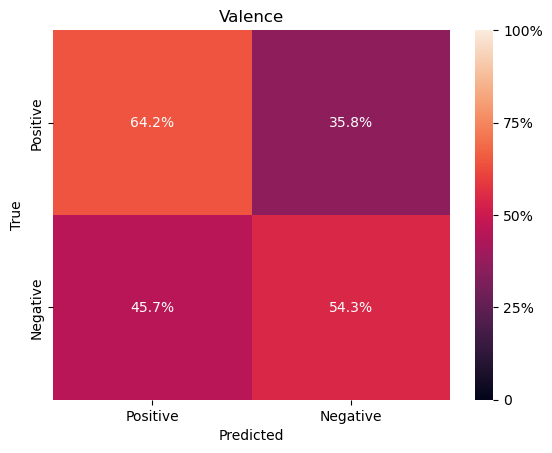

In [174]:
# display the confusion matrix
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(clf_val, X, ravel(y_val), cv=logo, groups=groups_class)

conf_mat = confusion_matrix(ravel(y_val), y_pred, normalize='true')

print(conf_mat)

# plot the confusion matrix

val_labels = ['Positive', 'Negative']
ax = sns.heatmap(conf_mat, annot=True, 
            fmt='.1%', 
            xticklabels=val_labels, 
            yticklabels=val_labels, vmin=0, vmax=1)


cbar = ax.collections[0].colorbar
cbar.set_ticks([0, .25, 0.5, .75, 1])
cbar.set_ticklabels(['0', '25%', '50%', '75%', '100%'])

plt.xlabel('Predicted')
plt.ylabel('True')

# title
plt.title('Valence')

plt.show()


## 4.2 Arousal

In [175]:
y_aro = np.unique(y, return_inverse=True)[1]

# replace the values 0 and 3 with 0 and the values 1 and 2 with 1
y_aro = np.where(y_aro == 0, 0, y_aro)
y_aro = np.where(y_aro == 1, 0, y_aro)

y_aro = np.where(y_aro == 3, 1, y_aro)
y_aro = np.where(y_aro == 2, 1, y_aro)

In [176]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split

from sklearn.model_selection import LeaveOneGroupOut


clf_aro = RandomForestClassifier(max_depth=None, random_state=0)

# X = np.random.rand(X.shape[0], X.shape[1])

scores = cross_val_score(clf_aro, X, ravel(y_aro), cv=logo, groups=groups_class, scoring='accuracy')

print(np.mean(scores), scores.std())

print (scores)

0.5833333333333334 0.22047927592204922
[0.54166667 0.5        0.5        0.5        0.45833333 0.625
 0.66666667 0.5        1.         0.75       1.         0.08333333
 0.66666667 0.58333333 0.375     ]


[[0.59259259 0.40740741]
 [0.43209877 0.56790123]]


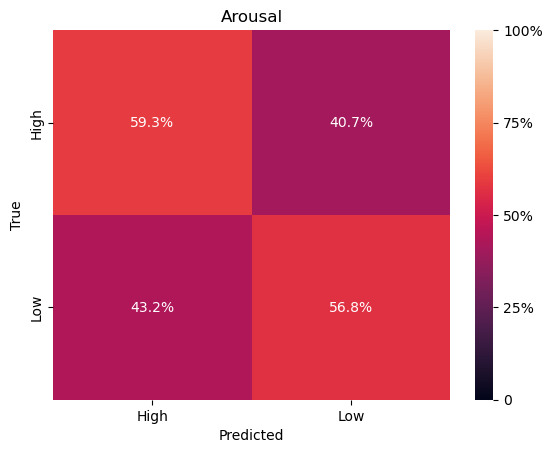

In [258]:
# display the confusion matrix
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(clf_aro, X, ravel(y_aro), cv=logo, groups=groups_class)

conf_mat = confusion_matrix(ravel(y_aro), y_pred, normalize='true')

print(conf_mat)

# plot the confusion matrix
aro_labels = ['High', 'Low']
ax = sns.heatmap(conf_mat, annot=True, 
            fmt='.1%', 
            xticklabels=aro_labels, 
            yticklabels=aro_labels, vmin=0, vmax=1)

cbar = ax.collections[0].colorbar
cbar.set_ticks([0, .25, 0.5, .75, 1])
cbar.set_ticklabels(['0', '25%', '50%', '75%', '100%'])

plt.xlabel('Predicted')
plt.ylabel('True')

# title
plt.title('Arousal')

plt.show()

# 5. Analyze results

In [178]:
# import raw snirf to get channel montage

# Participant id.
p_id = 'S03'

# write data_path using p_id.
data_path = os.path.join('..', 'data', 'dataset', p_id, 'nirs')

print(data_path)

# Run id.
run_id = '1'


# Create an empty list to store the raw intensity data
raw_intensity = []

# Get files with .snirf extension using os
snirf_files = [os.path.join(data_path, f) for f in os.listdir(data_path) if f.endswith('.snirf')]

# select file that contains run_id in its name
snirf_file = [f for f in snirf_files if run_id in f]

if snirf_file:
    # Load the data in snirf_file
    raw_data = mne.io.read_raw_snirf(snirf_file[0], preload=True, verbose=True)

    raw_data.load_data()

else:
    
    print('No snirf file found')

raw_data.info

# Convert NIRS raw data to optical density.
raw_od = mne.preprocessing.nirs.optical_density(raw_data)

raw_haemo = mne.preprocessing.nirs.beer_lambert_law(raw_od, ppf=6.0)


../data/dataset/S03/nirs
Loading /Users/brunomiguel/Documents/GitHub/NIRS-pytools/scripts/../data/dataset/S03/nirs/sub-S03_task-music_run-1.snirf
Reading 0 ... 2412  =      0.000 ...   191.513 secs...


In [179]:
data = mne.io.read_raw_fif('../data/dataset/derivatives/mne-nirs/S03/sub-S03_run-1_long_haemo.fif')

Opening raw data file ../data/dataset/derivatives/mne-nirs/S03/sub-S03_run-1_long_haemo.fif...
    Range : 9 ... 2279 =      0.715 ...   180.953 secs
Ready.


In [180]:
# Download anatomical locations
subjects_dir = os.path.join(mne.datasets.sample.data_path(), 'subjects')
mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir)

identity_trans = mne.transforms.Transform("head", "mri")


0 files missing from root.txt in /Users/brunomiguel/mne_data/MNE-sample-data/subjects
0 files missing from bem.txt in /Users/brunomiguel/mne_data/MNE-sample-data/subjects/fsaverage


In [181]:
import mne

brain = mne.viz.Brain('fsaverage', 
                      subjects_dir=subjects_dir, 
                      background='w', 
                      cortex='.5',
                    title='NIRS channels',
);

brain.add_sensors(data.info, 
                  trans=identity_trans, 
                  fnirs=['channels', 'pairs', 'sources', 'detectors'],)

brain.show_view(azimuth=90, elevation=0, distance=450)

# save the brain plot
#brain.save_image('brain_hor_plot.png')


#brain.add_sensors(raw_data.info, trans="fsaverage", fnirs=["channels", "pairs"])

Channel types::	hbo: 98, hbr: 98


import pyvista as pv
from pyvistaqt import BackgroundPlotter

p = BackgroundPlotter()
p.add_mesh(pv.Cone())

In [182]:

## This function is working for plotting source and detector pairs (106 channels) in 3D head model
fig = mne.viz.create_3d_figure(size=(800, 600), bgcolor='white')

surfaces=dict(brain=0.4, outer_skull=0.6, head=None)

fig = mne.viz.plot_alignment(data.info, 
                             trans=identity_trans,
                             subject='fsaverage',
                             coord_frame='mri',
                             surfaces=surfaces,
							 fnirs=['channels', 'pairs',
									'sources', 'detectors'],
                             fig=fig)

Using outer_skin.surf for head surface.
Channel types::	hbo: 98, hbr: 98


In [183]:
# create a random array of 268 values
#t_data = np.random.rand(98)

In [248]:
# select only hbo channels

# Return channels with a long source detector separation.
long_haemo = mne_nirs.channels.get_long_channels(raw_haemo)



In [247]:
hbo_ch=long_haemo.pick(picks='hbo')


In [219]:
hbo_ch_plot=hbo_ch.ch_names

# create a copy hbo_ch_plot
hbo_ch_plot_copy = hbo_ch_plot.copy()

# if any element of sorted_channels is NOT in hbo_ch_plot_copy replace it with ' '
for i, ch in enumerate(hbo_ch_plot_copy):
    if ch not in sorted_channels:
        hbo_ch_plot_copy[i] = ' '

# remove the last token from the channel names
hbo_ch_plot_copy = [ch[:-3] for ch in hbo_ch_plot_copy]

<Figure size 1000x1000 with 0 Axes>

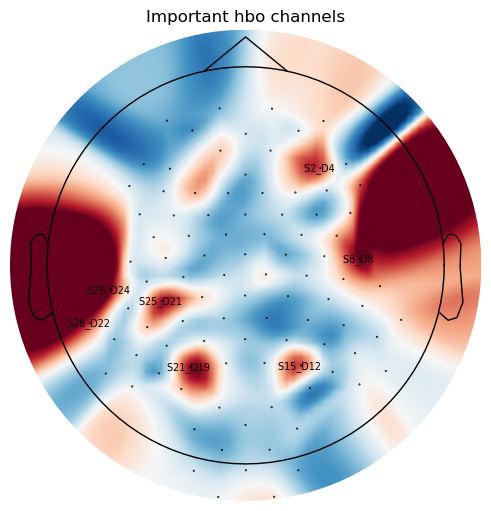

In [244]:
# Set the size of the figure

import matplotlib


fig = plt.figure(figsize=(10, 10))


im, _ = mne.viz.plot_topomap(mean_feature_coef_hbo, 
                     hbo_ch.info,
                     sensors=True,
                     outlines='head', 
                     contours=0,
                     sphere=0.12,
                     cmap='RdBu_r', 
                     size=5, 
                     names=hbo_ch_plot_copy,
                     show=False,
                     )

plt.title('Important hbo channels')



plt.show()



In [255]:
hbr_ch=long_haemo.pick(picks='hbr')

hbr_ch_plot=hbr_ch.ch_names

# create a copy hbo_ch_plot
hbr_ch_plot_copy = hbr_ch_plot.copy()

# if any element of sorted_channels is NOT in hbo_ch_plot_copy replace it with ' '
for i, ch in enumerate(hbr_ch_plot_copy):
    if ch not in sorted_channels:
        hbr_ch_plot_copy[i] = ' '

# remove the last token from the channel names
hbr_ch_plot_copy = [ch[:-3] for ch in hbr_ch_plot_copy]


In [256]:
hbr_ch_plot_copy

['',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 'S20_D16 ',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 '',
 'S28_D24 ',
 '',
 '',
 '',
 '',
 '',
 'S30_D27 ',
 '',
 '',
 '',
 '',
 '']

<Figure size 1000x1000 with 0 Axes>

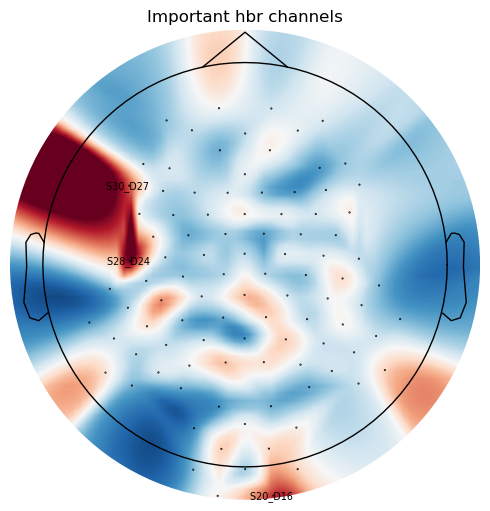

In [260]:
# Set the size of the figure

fig = plt.figure(figsize=(10, 10))

im, _ = mne.viz.plot_topomap(mean_feature_coef_hbr, 
                     hbr_ch.info,
                     sensors=True,
                     outlines='head', 
                     contours=0,
                     sphere=0.1225,
                     cmap='RdBu_r', 
                     size=5, 
                     names=hbr_ch_plot_copy,
                     show=False
                     );


plt.title('Important hbr channels')


plt.show()